# Charts: Ireland vs the EU

Team: The Foreigners. Chart 2 of the final visualization package (Jenny), with an extra chart that ranks the 27 EU countries for 2025.

The charts answer question 2: is the pattern in Ireland different from the EU average? They use the prepared table `unmet_need_by_reason` from the data audit (`Data_Audit_Pandas_v4.ipynb`), which holds the share of people aged 16 and over who needed a medical examination and did not get one, by main reason.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

PREPARED = Path("data/prepared")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

ORANGE = "#eb6834"  # waiting
BLUE = "#2a78d6"  # cost
GREY = "#898781"  # EU average
LIGHT = "#d3d1c7"  # other EU countries

unmet = pd.read_csv(PREPARED / "unmet_need_by_reason_v1_2026-11-11.csv")
unmet.head()

,area,area_code,group,year,reason,pct,flag,is_break
0,Austria,AT,Other EU country,2016,Too expensive,0.2,NaN,False
1,Austria,AT,Other EU country,2017,Too expensive,0.2,NaN,False
2,Austria,AT,Other EU country,2018,Too expensive,0.1,NaN,False
3,Austria,AT,Other EU country,2019,Too expensive,0.2,NaN,False
4,Austria,AT,Other EU country,2020,Too expensive,0.1,NaN,False


The title, the finding under it and the source are written in the same way on both charts, so one small function does it.

In [2]:
def add_text(fig, title, subtitle, top, gap):
    # the title, the finding under it, and the source at the bottom
    fig.text(0.01, top, title, fontsize=14, fontweight="bold")
    fig.text(0.01, top - gap, subtitle, fontsize=10.5)
    fig.text(0.01, 0.015, "Source: Eurostat EU-SILC", fontsize=9, color=GREY)

## Chart 2: Ireland vs the EU average

**Why this chart type?** The data is two series (Ireland and the EU average) over ten years, so a line chart shows how each moves and the gap between them in every year. Waiting and cost are shown side by side on the same 0 to 3% scale, so the two reasons can be compared at a glance. A pie chart has no time axis, and stacked bars would hide the gap between Ireland and the EU.

### 2.1 Pick Ireland and the EU average

In [3]:
ireland = unmet[unmet["group"] == "Ireland"]
eu = unmet[unmet["group"] == "EU average"]


def series(table, reason):
    # one reason as a list of values, with the year as the index
    return table[table["reason"] == reason].set_index("year")["pct"]


waiting_ie, waiting_eu = series(ireland, "Waiting list"), series(eu, "Waiting list")
cost_ie, cost_eu = series(ireland, "Too expensive"), series(eu, "Too expensive")

print("Waiting 2025: Ireland", waiting_ie[2025], "| EU", waiting_eu[2025])
print("Cost 2025: Ireland", cost_ie[2025], "| EU", cost_eu[2025])

assert (waiting_ie > waiting_eu).all()  # Ireland is above the EU average on waiting in every year
assert (cost_ie.loc[2020:2025] < cost_eu.loc[2020:2025]).all()  # and below it on cost from 2020
assert (waiting_ie[2025], waiting_eu[2025], cost_ie[2025], cost_eu[2025]) == (2.1, 1.2, 0.6, 1.0)
assert (
    (waiting_ie - waiting_eu).round(1).agg(["min", "max"]) == [0.2, 1.4]
).all()  # the waiting gap in points

Waiting 2025: Ireland 2.1 | EU 1.2
Cost 2025: Ireland 0.6 | EU 1.0


The checks confirm that Ireland's waiting value is above the EU average in all ten years, and that its cost value is below the EU average in every year from 2020 to 2025.

### 2.2 A function to draw one panel

The two reasons have the same layout, so the drawing steps are written once and used for each panel. The function draws Ireland and the EU average, with a legend, a y-axis value every 0.2% and a label for every year. We kept the chart to these main parts and left out values on the points, because they made the chart look cluttered.

In [4]:
years = list(range(2016, 2026))


def draw_panel(ax, ie, e, colour, heading):
    ax.plot(years, e, color=GREY, linestyle="--", linewidth=2, label="EU27 average")
    ax.plot(years, ie, color=colour, linewidth=3, label="Ireland")

    ax.set_title(heading, fontsize=12)
    ax.set_ylim(0, 3)
    ax.set_yticks([i / 5 for i in range(16)])  # a value every 0.2%, like the data
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=1))  # 0.2 is shown as 0.2%
    ax.tick_params(axis="y", labelsize=8.5, labelleft=True)  # keep the labels on both panels
    ax.set_xticks(years)  # every year
    ax.grid(axis="y", color="#efefef", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=10)

### 2.3 Chart 2: waiting list and cost side by side

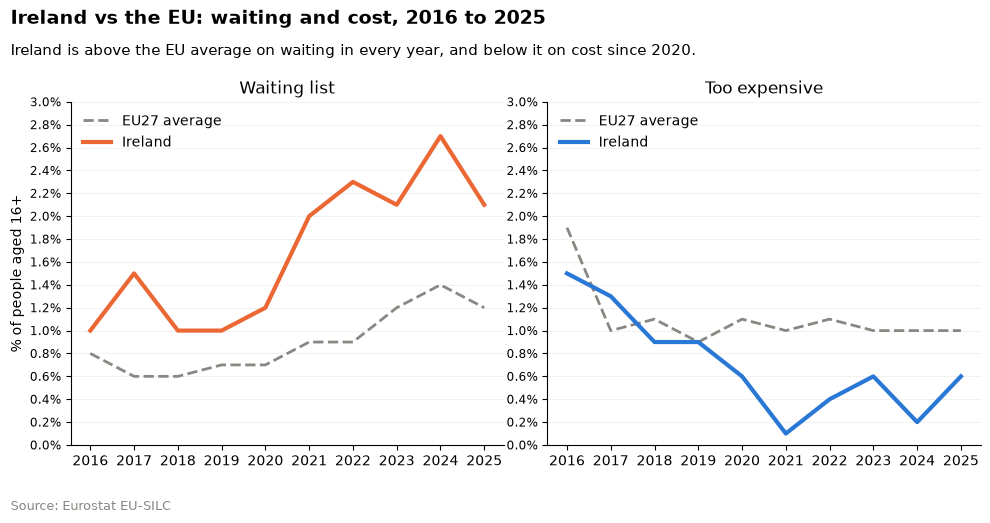

In [5]:
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 5.2))  # two panels with the same y-axis
draw_panel(axes[0], waiting_ie, waiting_eu, ORANGE, "Waiting list")
draw_panel(axes[1], cost_ie, cost_eu, BLUE, "Too expensive")
axes[0].set_ylabel("% of people aged 16+")

add_text(
    fig,
    "Ireland vs the EU: waiting and cost, 2016 to 2025",
    "Ireland is above the EU average on waiting in every year, and below it on cost since 2020.",
    top=0.95,
    gap=0.06,
)
fig.subplots_adjust(top=0.8, bottom=0.14, left=0.07, right=0.98, wspace=0.1)
fig.savefig(FIGURES / "chart2_ireland_vs_eu.png", dpi=200)
plt.show()

Each panel is one reason for going without care. The coloured line is Ireland and the grey dashed line is the EU27 average. A higher line means more people gave that reason. Both panels use the same 0 to 3% scale, so the waiting values can be compared directly with the cost values.


**Waiting list:** Ireland rises from 1.0% in 2016 to 2.1% in 2025. The biggest jump is from 1.2% in 2020 to 2.0% in 2021, and the highest value is 2.7% in 2024. The EU average moves from 0.8% to 1.2%, with a peak of 1.4% in 2024. Ireland is above the EU average in every year, by between 0.2 points (2016) and 1.4 points (2022), and by 0.9 points in 2025.

**Too expensive:** Ireland falls from 1.5% in 2016 to 0.6% in 2025, with lows of 0.1% in 2021 and 0.2% in 2024. The EU average sits close to 1.0% from 2017 (after 1.9% in 2016). Ireland is below the EU average in every year from 2020 to 2025. Before 2020 it was mixed: below in 2016 and 2018, above in 2017 and level in 2019.

**Both:** in 2016 more people in Ireland gave cost (1.5%) than waiting (1.0%). In 2025 waiting (2.1%) is about three and a half times cost (0.6%).

- The values are small, so a difference of 0.1 or 0.2 points can be survey noise. Look at the direction over several years, not one year.
- Eurostat flags a break in Ireland's series in 2019 and 2020, so those two years are not fully comparable with the others. The chart does not mark them, to keep it simple.
- The survey covers all medical care, not only hospital care, and the EU average is Eurostat's own weighted figure.
- The chart shows a pattern, not a cause.

## Chart 2b: where Ireland sits in 2025

**Why this chart type.** Here we compare one value per country in a single year, so the data is categories, not a time series. Horizontal bars sorted from highest to lowest show the order at a glance, from a zero baseline, and the long country names fit. A line chart would suggest a time trend that is not there, and a pie chart cannot show differences of a few percentage points. Waiting and cost are side by side on the same scale.

### 2b.1 Rank the countries

In [6]:
y2025 = unmet[unmet["year"] == 2025]
ranked = {}
for reason in ["Waiting list", "Too expensive"]:
    ranked[reason] = (
        y2025[y2025["reason"] == reason].sort_values("pct", ascending=False).reset_index(drop=True)
    )

countries = {
    r: t[t["group"] != "EU average"] for r, t in ranked.items()
}  # the 27 countries, without the average
average = {r: t.loc[t["group"] == "EU average", "pct"].iloc[0] for r, t in ranked.items()}
rank = {r: list(c["area"]).index("Ireland") + 1 for r, c in countries.items()}  # 1 = highest
above = {
    r: int((c["pct"] > average[r]).sum()) for r, c in countries.items()
}  # countries above the EU average
print("Ireland's rank:", rank, "| countries above the EU average:", above)

assert all(len(t) == 28 and t["pct"].notna().all() for t in ranked.values())
assert rank == {"Waiting list": 8, "Too expensive": 9}
assert above == {"Waiting list": 13, "Too expensive": 5}
assert (countries["Waiting list"]["pct"] <= 2.0).sum() == 19  # most countries are at 2% or below on waiting
assert (countries["Too expensive"]["pct"] <= 0.5).sum() == 18  # and at 0.5% or below on cost

Ireland's rank: {'Waiting list': 8, 'Too expensive': 9} | countries above the EU average: {'Waiting list': 13, 'Too expensive': 5}


All 28 values (27 countries and the EU average) are present for 2025. Ireland ranks 8th highest of the 27 countries on waiting (2.1%) and 9th highest on cost (0.6%).

### 2b.2 A function to draw one ranking

Both rankings have the same layout, so the drawing steps are written once. The function sorts the countries from highest to lowest, highlights Ireland, shows the EU average in grey and writes the value at the end of each bar.

In [7]:
def draw_bars(ax, reason, colour, heading):
    table = ranked[reason]
    palette = {"Ireland": colour, "EU average": GREY, "Other EU country": LIGHT}
    ax.barh(table["area"], table["pct"], color=table["group"].map(palette).tolist(), height=0.7)
    ax.invert_yaxis()  # highest at the top
    for i, value in enumerate(table["pct"]):
        ax.text(
            value + 0.15, i, f"{value:.1f}%", va="center", fontsize=8.5
        )  # the value at the end of each bar

    ax.set_title(heading, fontsize=12)
    ax.set_xlim(0, 10)
    ax.set_xticks(range(0, 11, 2))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.tick_params(axis="y", labelsize=8.5, length=0)
    ax.spines[["top", "right"]].set_visible(False)
    for label in ax.get_yticklabels():  # Ireland and the average in bold
        if label.get_text() in ("Ireland", "EU27 average"):
            label.set_fontweight("bold")

### 2b.3 Chart 2b: waiting list and cost side by side

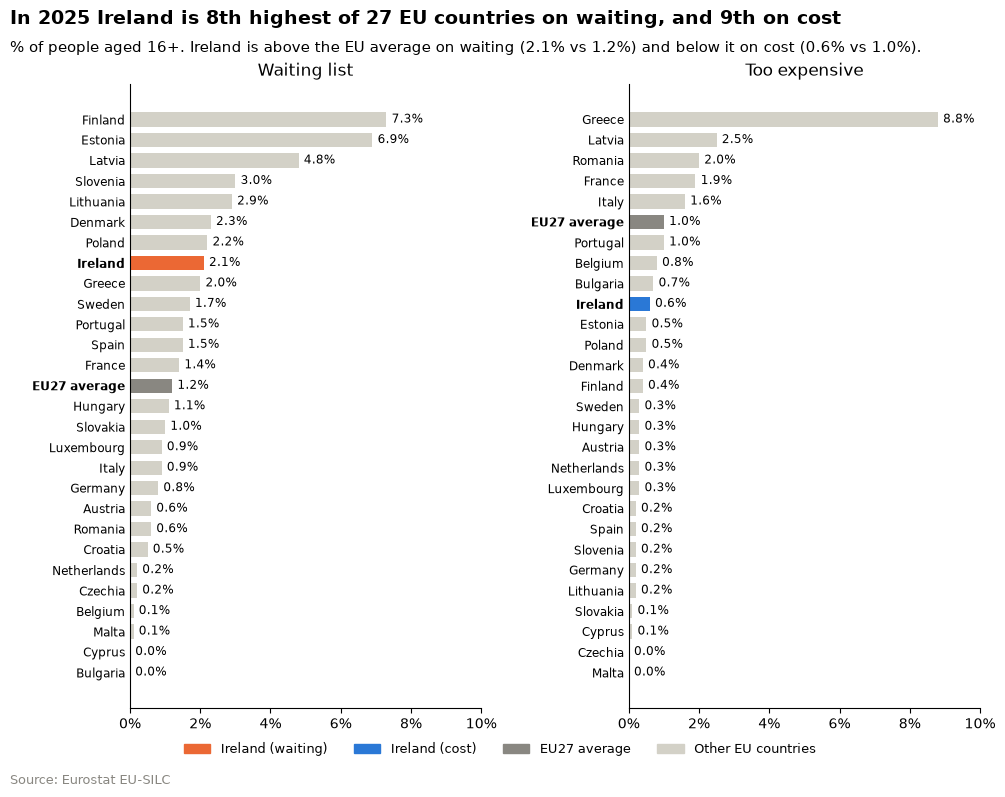

In [8]:
fig, axes = plt.subplots(1, 2, sharex=True, figsize=(10, 8))  # two panels with the same x-axis
draw_bars(axes[0], "Waiting list", ORANGE, "Waiting list")
draw_bars(axes[1], "Too expensive", BLUE, "Too expensive")

legend = [
    Patch(color=ORANGE, label="Ireland (waiting)"),
    Patch(color=BLUE, label="Ireland (cost)"),
    Patch(color=GREY, label="EU27 average"),
    Patch(color=LIGHT, label="Other EU countries"),
]
fig.legend(
    handles=legend, loc="lower center", ncol=4, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 0.035)
)

add_text(
    fig,
    "In 2025 Ireland is 8th highest of 27 EU countries on waiting, and 9th on cost",
    "% of people aged 16+. Ireland is above the EU average on waiting (2.1% vs 1.2%) and below it on cost (0.6% vs 1.0%).",
    top=0.965,
    gap=0.035,
)
fig.subplots_adjust(top=0.89, bottom=0.11, left=0.13, right=0.98, wspace=0.42)
fig.savefig(FIGURES / "chart2b_ranking_2025.png", dpi=200)
plt.show()

Each bar is one country's value for 2025, with the highest at the top. Ireland is coloured, the EU27 average is dark grey and the other countries are light grey. The value is written at the end of each bar, and both panels use the same 0 to 10% scale.


**Waiting list:** Ireland (2.1%) is 8th highest of the 27 countries and above the EU average (1.2%). Thirteen countries are above the average. Finland (7.3%), Estonia (6.9%) and Latvia (4.8%) are far ahead, while 19 of the 27 countries are at 2.0% or below.

**Too expensive:** Ireland (0.6%) is 9th highest but below the EU average (1.0%). Only five countries are above the average. Greece (8.8%) is far ahead of Latvia (2.5%), Romania (2.0%) and France (1.9%), and 18 of the 27 countries are at 0.5% or below.

**Both:** Ireland ranks similarly on both (8th and 9th highest), but it is above the EU average on waiting and below it on cost. Most countries have very low cost values, so Ireland's 0.6% is only just above that group.

- The ranking shows the order, not the size of the gaps. Ireland (2.1%) and Poland (2.2%) are close, while Finland is far above both.
- It is one year only, and countries differ in how they run the survey and in their health systems.
- The chart shows a pattern, not a cause.